# Cluster-Permutation Test: Does wCSET Beat CSET Across the Degradation-Severity Range?

Same question as `pilot_noise_cluster_permutation.ipynb`, applied to the degradation
pilot (2a) instead of the noise sweep: does wCSET significantly outperform CSET, and
over which contiguous range of corruption severity? Only one comparison here --
study 2 was scoped to `wCSET` vs `CSET` from the start, not the 6-method set used in
the noise sweep.

## Region is the subject here too -- an earlier version of this notebook got this wrong

`pilot_degradation_02_solve.py` reconstructs the *same* 208 simulated trials (same
region, same repetition, same underlying signal+noise) under all 6 severity
connectomes, so `(region, repetition)` pairs are genuinely matched across severity
-- unlike the noise sweep, where repetitions weren't matched at all. An earlier
version of this notebook used that to treat all 208 `(region, repetition)` pairs as
independent permutation subjects. That's wrong: `pilot_degradation_variance_components.json`
shows `sigma2_method_region` (genuine region-level structure in the wCSET-vs-CSET
difference) is substantial for localization error (41-115 across severities) -- the
8 repetitions within a region share a real regional bias, they aren't independent
with respect to this effect. Treating them as 208 independent subjects dilutes that
correlation in the permutation null and makes the test anti-conservative, exactly
the mistake already caught and fixed once for the noise-sweep version.

**Fixed the same way**: region is the subject (26, not 208), matched repetitions are
averaged per `(region, severity)` cell first -- same design as the noise-sweep
notebook, just with severity instead of SNR as the swept axis, and one comparison
(`wCSET` vs `CSET`) instead of five.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
HIGHER_IS_BETTER = {"localization_error_hrp": False, "ap_hrp": True, "ap_pp": True, "correlation_auc": True}
REFERENCE_METHOD = "wcset"
COMPETITOR = "cset"
SEVERITY_ORDER = [0, 20, 40, 60, 80, 100]
N_PERM = 3000
CLUSTER_ALPHA = 0.05

df = pd.read_csv("pilot_degradation_outcomes.tsv", sep="\t")
regions = sorted(df["region"].unique())
k = len(regions)
print(f"{len(df)} rows, {k} regions, severities {SEVERITY_ORDER}")

2496 rows, 26 regions, severities [0, 20, 40, 60, 80, 100]


## Helper functions

`region_series` builds the `(26 regions, 6 severities)` paired-difference matrix,
averaging the 8 matched repetitions per `(region, severity)` cell first -- same
convention as the noise-sweep notebook's `region_series`, just averaging over
repetitions that happen to be exactly matched here rather than independent draws.

In [2]:
def region_series(outcome):
    """(k, 6) matrix: per-region, per-severity mean paired difference (wcset - cset),
    sign-adjusted so positive = wcset better, averaged over the 8 matched repetitions."""
    sign = 1.0 if HIGHER_IS_BETTER[outcome] else -1.0
    wide_wcset = df[df["method"] == REFERENCE_METHOD].groupby(["region", "percentage"])[outcome].mean().unstack()[SEVERITY_ORDER]
    wide_comp = df[df["method"] == COMPETITOR].groupby(["region", "percentage"])[outcome].mean().unstack()[SEVERITY_ORDER]
    diff = sign * (wide_wcset - wide_comp)
    return diff.reindex(regions).to_numpy()


def cluster_permutation_test(D, cluster_alpha=CLUSTER_ALPHA, n_perm=N_PERM, seed=0):
    """D: (k, S) array, one series per region (subject). Region-level permutation:
    flips each row's sign consistently across all S columns."""
    k, S = D.shape
    rng = np.random.default_rng(seed)
    t_crit = stats.t.ppf(1 - cluster_alpha / 2, df=k - 1)

    def compute_t(Dperm):
        m = Dperm.mean(axis=0)
        se = Dperm.std(axis=0, ddof=1) / np.sqrt(k)
        return m / se

    def find_clusters(t):
        clusters = []
        sign_mask = np.where(t > t_crit, 1, np.where(t < -t_crit, -1, 0))
        i = 0
        while i < S:
            if sign_mask[i] != 0:
                j = i
                while j < S and sign_mask[j] == sign_mask[i]:
                    j += 1
                clusters.append((i, j - 1, np.sum(t[i:j]), sign_mask[i]))
                i = j
            else:
                i += 1
        return clusters

    t_obs = compute_t(D)
    clusters_obs = find_clusters(t_obs)

    max_pos_null = np.zeros(n_perm)
    min_neg_null = np.zeros(n_perm)
    for p in range(n_perm):
        flips = rng.choice([-1.0, 1.0], size=k)
        t_p = compute_t(D * flips[:, None])
        clusters_p = find_clusters(t_p)
        pos = [c[2] for c in clusters_p if c[3] == 1]
        neg = [c[2] for c in clusters_p if c[3] == -1]
        max_pos_null[p] = max(pos) if pos else 0.0
        min_neg_null[p] = min(neg) if neg else 0.0

    results = []
    for (i, j, mass, sgn) in clusters_obs:
        pval = ((np.sum(max_pos_null >= mass) + 1) / (n_perm + 1) if sgn == 1
                else (np.sum(min_neg_null <= mass) + 1) / (n_perm + 1))
        results.append({"severity_start": SEVERITY_ORDER[i], "severity_end": SEVERITY_ORDER[j],
                         "mass": mass, "sign": sgn, "p_value": pval})

    return {"t_obs": t_obs, "clusters": results}

## Run for all 4 outcomes (single comparison: wCSET vs CSET)

In [3]:
all_results = []
series_cache = {}
for outcome in OUTCOMES:
    D = region_series(outcome)
    series_cache[outcome] = D
    seed = abs(hash(outcome)) % (2**31)
    res = cluster_permutation_test(D, seed=seed)
    if res["clusters"]:
        for c in res["clusters"]:
            all_results.append({"outcome": outcome, **c})
    else:
        all_results.append({"outcome": outcome, "severity_start": None, "severity_end": None,
                             "mass": None, "sign": None, "p_value": None})

results_df = pd.DataFrame(all_results)
results_df.to_csv("pilot_degradation_cluster_permutation_results.tsv", sep="\t", index=False)
pd.set_option("display.width", 160)
results_df

,outcome,severity_start,severity_end,mass,sign,p_value
0,localization_error_hrp,0,0,2.923763,1,0.026658
1,localization_error_hrp,40,80,9.985338,1,0.002333
2,ap_hrp,0,80,21.841574,1,0.000333
3,ap_pp,0,80,23.148157,1,0.000333
4,correlation_auc,0,80,26.645289,1,0.000333


## Difference series per outcome, with significant severity ranges shaded

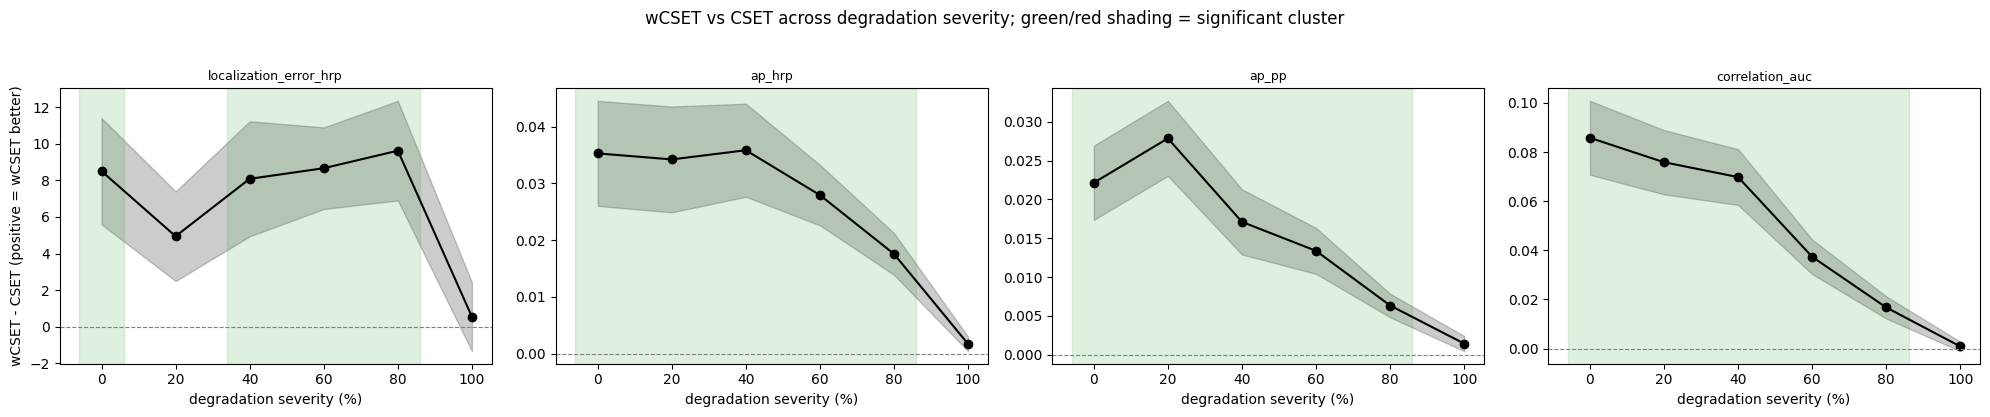

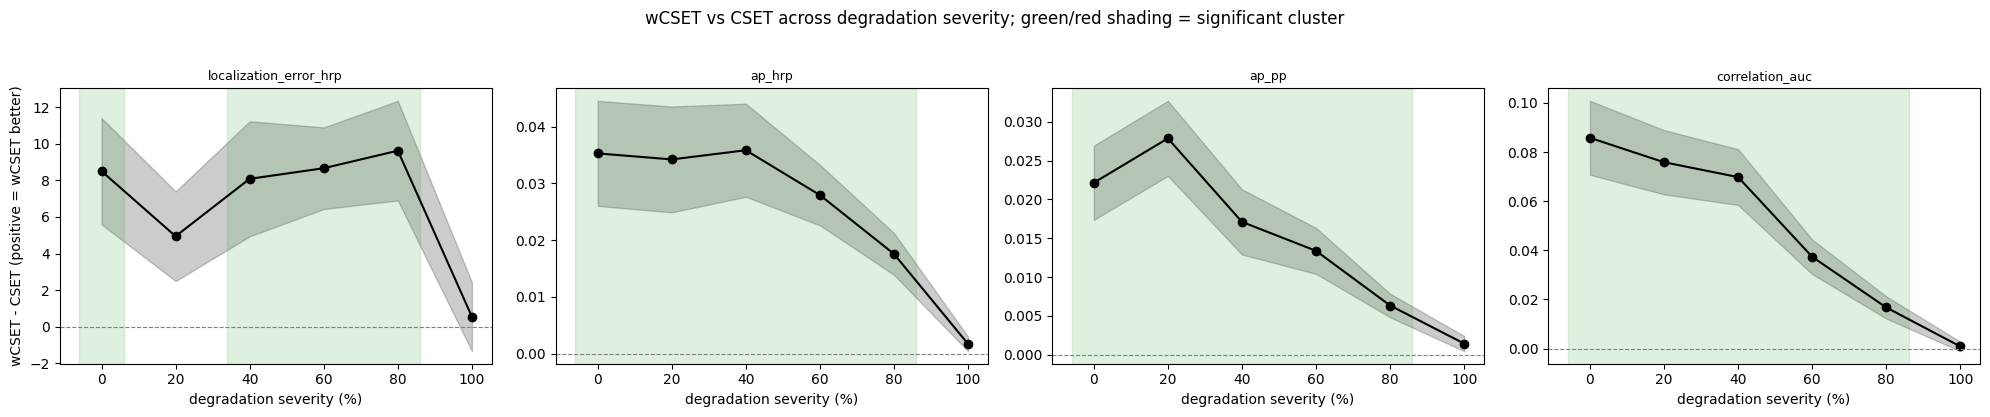

In [4]:
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(5 * len(OUTCOMES), 4))
for ax, outcome in zip(axes, OUTCOMES):
    D = series_cache[outcome]
    mean_series = D.mean(axis=0)
    se_series = D.std(axis=0, ddof=1) / np.sqrt(k)
    x = np.arange(len(SEVERITY_ORDER))
    ax.plot(x, mean_series, marker="o", color="black")
    ax.fill_between(x, mean_series - se_series, mean_series + se_series, alpha=0.2, color="black")
    ax.axhline(0, ls="--", c="gray", lw=0.8)

    rows = results_df[(results_df["outcome"] == outcome) & (results_df["p_value"] < 0.05)]
    for _, row in rows.iterrows():
        i = SEVERITY_ORDER.index(row["severity_start"]); j = SEVERITY_ORDER.index(row["severity_end"])
        color = "tab:green" if row["sign"] == 1 else "tab:red"
        ax.axvspan(i - 0.3, j + 0.3, color=color, alpha=0.15)

    ax.set_title(outcome, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([str(s) for s in SEVERITY_ORDER])
    ax.set_xlabel("degradation severity (%)")

axes[0].set_ylabel("wCSET - CSET (positive = wCSET better)")
fig.suptitle("wCSET vs CSET across degradation severity; green/red shading = significant cluster", y=1.03)
fig.tight_layout()
fig.savefig("pilot_degradation_cluster_permutation_curves.png", dpi=130, bbox_inches="tight")
fig

## Reading the result

Green shading = a contiguous severity range where wCSET significantly beats CSET;
red = where CSET is significantly better. No shading = no significant cluster there.
26 regions here, same subject count and same design as the noise-sweep test --
directly comparable in resolving power, unlike the earlier (incorrect) 208-subject
version of this notebook.